# ML-06 — Signal Audit: Do the Flags Hold?

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

**Lane 2, Refresh / Content Opportunity Scoring.** This is the deeper, optional version of the two signal checks in `w04_baseline_score.ipynb`. It asks one question per test: does the data really show the story people tell about which pages decline?

**Same frame as W03 and W04.** One row = one page, features from March 2026, label `declined_next_month` = April impressions per day more than 20% below March. I call this the **main slice**.

**A second slice to check every verdict.** A real signal should survive in another period, noise should not. So every test also runs on **February → March**: the same build, one month earlier (features from February, label from March). It only serves as a check. No rule or model is fitted on it. June (the sealed month) is never read.

**How to run it:** same as W03. In Colab save your Hugging Face READ token as a Secret named `HF_TOKEN`. Outside Colab the notebook reads the `HF_TOKEN` environment variable or asks for it with `getpass`. The token is never printed.

In [1]:
%pip install -q duckdb huggingface_hub pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import getpass
from datetime import date
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The repo is public, so the token comes from a Colab Secret or an environment variable.
# It is never printed. getpass is only the last fallback.
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass
HF_TOKEN = HF_TOKEN or os.environ.get("HF_TOKEN") or getpass.getpass("Hugging Face READ token: ")

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
print("DuckDB connected. Hugging Face token loaded (not printed).")

DuckDB connected. Hugging Face token loaded (not printed).


## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

### Build the two slices

One function builds a page frame for any pair of months, with the W03 rules: a row on every day of the feature month, client GSC tracking started by day 1, at least 100 impressions in the feature month and a row on every day of the label month. For March → April it must give back the exact W03 frame.

In [3]:
REL = "hf://datasets/FlyRank/internship-warehouse"
LABEL = "declined_next_month"
MIN_IMPRESSIONS = 100
DECLINE_CUTOFF_PCT = -20
BIG_CLIENT_PAGES = 1000     # "large client" = 1,000+ pages in a slice (same cut as W03 and W04)
MIN_GROUP_N = 50            # no verdict from a group smaller than this (skill floor)
MIN_CELL_N = 30             # no per-client comparison from a cell smaller than this
GAP_POINTS = 5              # a gap under 5 percentage points counts as "no real difference"

con.execute(f"CREATE OR REPLACE VIEW dim_clients AS SELECT * FROM read_parquet('{REL}/dim_clients.parquet')")


def page_frame(feature_month, label_month, late_half_start):
    """One row per page: feature-month numbers + the next-month decline label (same rules as W03)."""
    first_day = pd.Timestamp(f"{feature_month}-01")
    feature_days = first_day.days_in_month
    label_days = pd.Timestamp(f"{label_month}-01").days_in_month
    early_days = (pd.Timestamp(late_half_start) - first_day).days
    late_days = feature_days - early_days
    raw = con.sql(f"""
        WITH feat AS (
            SELECT
                content_hash_id,
                ANY_VALUE(client_hash_id)                          AS client_hash_id,
                COUNT(*)                                           AS feature_rows,
                SUM(gsc_impressions)::BIGINT                       AS imp,
                SUM(gsc_clicks)::BIGINT                            AS clicks,
                SUM(gsc_impressions) FILTER (WHERE report_date >= DATE '{late_half_start}')::BIGINT AS imp_late,
                COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_days,
                SUM(gsc_sum_position) FILTER (WHERE gsc_data_available IS TRUE AND gsc_avg_position > 0)::BIGINT AS position_sum,
                SUM(gsc_impressions)  FILTER (WHERE gsc_data_available IS TRUE AND gsc_avg_position > 0)::BIGINT AS position_impressions
            FROM read_parquet('{REL}/fact_content_daily_performance/month={feature_month}/*.parquet')
            GROUP BY content_hash_id
        ),
        lab AS (  -- label month only: nothing below is a feature
            SELECT content_hash_id, COUNT(*) AS label_rows, SUM(gsc_impressions)::BIGINT AS imp_label
            FROM read_parquet('{REL}/fact_content_daily_performance/month={label_month}/*.parquet')
            GROUP BY content_hash_id
        )
        SELECT feat.*, c.gsc_data_start, lab.label_rows, lab.imp_label
        FROM feat
        LEFT JOIN dim_clients c USING (client_hash_id)
        LEFT JOIN lab USING (content_hash_id)
    """).df()
    keep = (raw["feature_rows"].eq(feature_days)
            & pd.to_datetime(raw["gsc_data_start"]).le(first_day)
            & raw["imp"].ge(MIN_IMPRESSIONS)
            & raw["label_rows"].eq(label_days))
    e = raw[keep].sort_values("content_hash_id").reset_index(drop=True)
    frame = pd.DataFrame({
        "content_hash_id": e["content_hash_id"],
        "client_hash_id": e["client_hash_id"],
        "imp_per_day": e["imp"] / feature_days,
        "clicks": e["clicks"],
        "imp": e["imp"],
        "ctr_pct": 100 * e["clicks"] / e["imp"],
        "avg_position": e["position_sum"] / e["position_impressions"],
        "gsc_share": e["gsc_days"] / feature_days,                     # share of days with search data
        "early_per_day": (e["imp"] - e["imp_late"]) / early_days,
        "late_per_day": e["imp_late"] / late_days,
    })
    frame = frame.astype({c: "float64" for c in frame.columns if c not in ("content_hash_id", "client_hash_id")})
    frame["slide_pct"] = 100 * (1 - frame["late_per_day"] / frame["early_per_day"].where(frame["early_per_day"] > 0))
    change_pct = 100 * (e["imp_label"] / label_days - frame["imp_per_day"]) / frame["imp_per_day"]
    frame[LABEL] = (change_pct < DECLINE_CUTOFF_PCT).astype(int)    # the % change itself is NOT kept
    return frame


main = page_frame("2026-03", "2026-04", "2026-03-16")    # main slice (W03 / W04 frame)
check = page_frame("2026-02", "2026-03", "2026-02-15")   # second slice, only to re-check verdicts
SLICES = {"Mar→Apr (main)": main, "Feb→Mar (check)": check}

summary = pd.DataFrame({name: {"pages": len(d), "clients": d["client_hash_id"].nunique(),
                               "large clients (1,000+ pages)": int((d.groupby("client_hash_id").size() >= BIG_CLIENT_PAGES).sum()),
                               "base rate": round(d[LABEL].mean(), 3)} for name, d in SLICES.items()}).T
summary = summary.astype({"pages": int, "clients": int, "large clients (1,000+ pages)": int})
print("Main slice matches W03 / W04 (94,496 pages, 38 clients, base rate 0.516):",
      len(main) == 94_496 and main["client_hash_id"].nunique() == 38 and round(main[LABEL].mean(), 3) == 0.516)
summary

Main slice matches W03 / W04 (94,496 pages, 38 clients, base rate 0.516): True


,pages,clients,"large clients (1,000+ pages)",base rate
Mar→Apr (main),94496,38,16,0.516
Feb→Mar (check),64881,26,7,0.248


The check slice is smaller (64,881 pages, 26 clients) because fewer clients were tracked from 1 February. Its base rate is much lower (24.8% vs 51.6%) because March was a stronger month than February for most sites. That is fine: I compare **directions and gaps** between groups inside each slice, not raw rates across slices.

### Distributions of the key fields (main slice)

In [4]:
def describe(series, name):
    s = series.dropna()
    q = s.quantile([0.01, 0.25, 0.5, 0.75, 0.9, 0.99])
    return {"field": name, "n": len(s), "zeros": f"{(s == 0).mean():.1%}", "mean": s.mean(), "p1": q[0.01], "p25": q[0.25],
            "median": q[0.5], "p75": q[0.75], "p90": q[0.9], "p99": q[0.99], "max": s.max(),
            "mean / median": s.mean() / q[0.5] if s.min() >= 0 and q[0.5] > 0 else np.nan}   # only for non-negative fields


fields = pd.DataFrame([
    describe(main["imp_per_day"], "impressions per day"),
    describe(main["clicks"] / 31, "clicks per day"),
    describe(main["ctr_pct"], "CTR % (page level)"),
    describe(main["avg_position"], "average position"),
    describe(main["slide_pct"], "slide % (early → late March)"),
    describe(main["gsc_share"] * 31, "days with search data (of 31)"),
]).set_index("field")

imp_sorted = np.sort(main["imp_per_day"].to_numpy())[::-1]
top1 = imp_sorted[: len(imp_sorted) // 100].sum() / imp_sorted.sum()
top10 = imp_sorted[: len(imp_sorted) // 10].sum() / imp_sorted.sum()
true_ctr = 100 * main["clicks"].sum() / main["imp"].sum()
print(f"Top 1% of pages hold {top1:.1%} of all March impressions, top 10% hold {top10:.1%}")
print(f"True CTR (all clicks / all impressions): {true_ctr:.3f}% vs mean of page CTRs {main['ctr_pct'].mean():.3f}%")
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(fields)

Top 1% of pages hold 18.1% of all March impressions, top 10% hold 58.2%
True CTR (all clicks / all impressions): 0.288% vs mean of page CTRs 0.248%


,n,zeros,mean,p1,p25,median,p75,p90,p99,max,mean / median
field,,,,,,,,,,,
impressions per day,94496,0.0%,92.74,3.35,9.39,26.68,86.42,218.15,974.08,"19,907.23",3.48
clicks per day,94496,37.5%,0.27,0.00,0.00,0.03,0.19,0.65,3.45,182.84,8.29
CTR % (page level),94496,37.5%,0.25,0.00,0.00,0.12,0.35,0.66,1.73,15.58,2.09
average position,94496,0.0%,14.60,1.31,4.90,8.38,19.21,34.45,72.05,115.66,1.74
slide % (early → late March),93161,0.0%,-97.05,"-1,259.38",-47.96,-4.29,26.63,51.59,88.33,100.00,NaN
days with search data (of 31),94496,0.0%,29.43,14.00,29.00,31.00,31.00,31.00,31.00,31.00,0.95


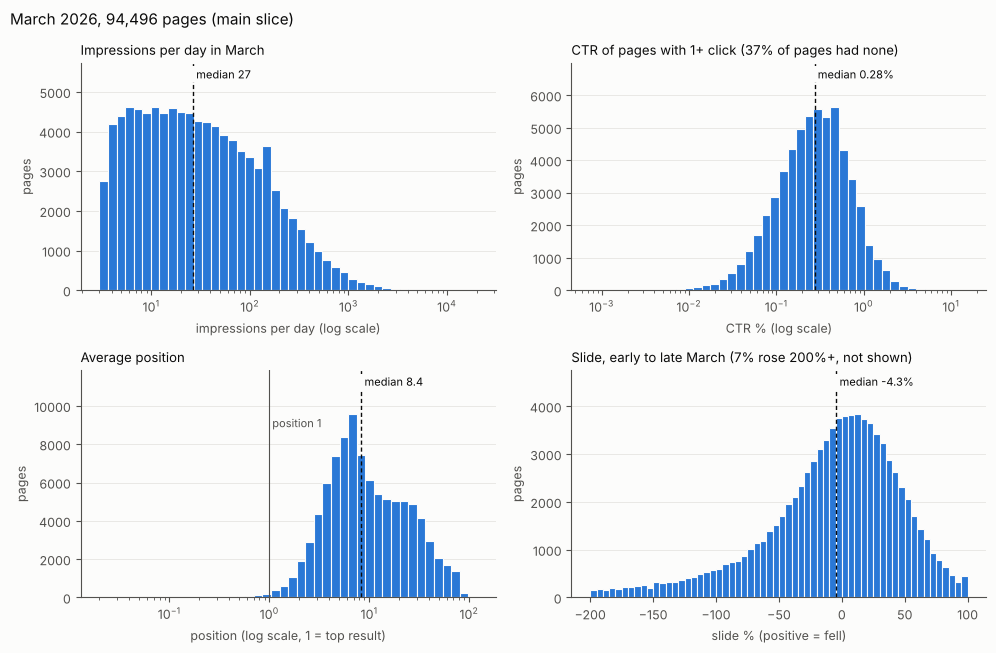

Saved ../figures/w04_signal_audit_distributions.png | pages that rose 200%+ from early to late March: 7.1%


In [5]:
# One figure, four panels. Single series per panel, so no legend. Log scales where the tail is long.
SERIES, SURFACE, INK, INK_2, GRID = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK_2, "axes.labelcolor": INK_2,
                     "xtick.color": INK_2, "ytick.color": INK_2, "axes.titlecolor": INK})

fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), facecolor=SURFACE)
clicked = main.loc[main["ctr_pct"] > 0, "ctr_pct"]
slide = main["slide_pct"].dropna()
rose_a_lot = (slide < -200).mean()
# (values to plot, bins, log x?, title, x label, median of ALL pages in the field, label format)
panels = [
    (main["imp_per_day"], np.logspace(np.log10(3), np.log10(20000), 45), True, "Impressions per day in March",
     "impressions per day (log scale)", main["imp_per_day"].median(), "{:,.0f}"),
    (clicked, np.logspace(np.log10(clicked.min()), np.log10(clicked.max()), 45), True,
     f"CTR of pages with 1+ click ({(main['ctr_pct'] == 0).mean():.0%} of pages had none)", "CTR % (log scale)",
     clicked.median(), "{:.2f}%"),
    (main["avg_position"], np.logspace(np.log10(0.02), np.log10(120), 45), True, "Average position",
     "position (log scale, 1 = top result)", main["avg_position"].median(), "{:.1f}"),
    (slide[slide >= -200], np.linspace(-200, 100, 61), False,
     f"Slide, early to late March ({rose_a_lot:.0%} rose 200%+, not shown)", "slide % (positive = fell)",
     slide.median(), "{:.1f}%"),
]
for ax, (values, bins, log_x, title, xlabel, med, fmt) in zip(axes.ravel(), panels):
    ax.set_facecolor(SURFACE)
    ax.hist(values, bins=bins, color=SERIES, edgecolor=SURFACE, linewidth=0.8)
    top = ax.get_ylim()[1] * 1.18
    ax.set_ylim(0, top)
    ax.axvline(med, color=INK, linewidth=1, linestyle=(0, (3, 2)))
    ax.text(med, top * 0.98, " median " + fmt.format(med) + " ", color=INK, fontsize=8, va="top",
            bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1})
    if log_x:
        ax.set_xscale("log")
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("pages")
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1, 0].axvline(1, color=INK_2, linewidth=0.8)
axes[1, 0].text(1, axes[1, 0].get_ylim()[1] * 0.75, " position 1", color=INK_2, fontsize=8)
fig.suptitle(f"March 2026, {len(main):,} pages (main slice)", x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()

FIG_DIR = Path("../figures") if Path.cwd().name == "notebooks" else Path("work/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig_path = FIG_DIR / "w04_signal_audit_distributions.png"
fig.savefig(fig_path, dpi=150, facecolor=SURFACE)
plt.show()
print(f"Saved {fig_path} | pages that rose 200%+ from early to late March: {rose_a_lot:.1%}")

In [6]:
# Why heavy tails matter: the same volume signal measured three ways
pearson_raw = np.corrcoef(main["imp_per_day"], main[LABEL])[0, 1]
pearson_log = np.corrcoef(np.log1p(main["imp_per_day"]), main[LABEL])[0, 1]
spearman = main["imp_per_day"].corr(main[LABEL], method="spearman")
print(f"Impressions per day vs {LABEL}: Pearson on raw values {pearson_raw:+.3f} | Pearson on log1p {pearson_log:+.3f} | Spearman {spearman:+.3f}")

# The odd pages from W03: average position below 1, which Google never shows
odd = main["avg_position"] < 1
odd_check = check["avg_position"] < 1
print(f"Average position below 1: {odd.sum()} pages from {main.loc[odd, 'client_hash_id'].nunique()} clients "
      f"({odd.mean():.1%}) | decline rate {main.loc[odd, LABEL].mean():.3f} vs {main.loc[~odd, LABEL].mean():.3f} for the rest")
print(f"Same in the check slice: {odd_check.sum()} pages | decline rate {check.loc[odd_check, LABEL].mean():.3f} vs {check.loc[~odd_check, LABEL].mean():.3f}")

Impressions per day vs declined_next_month: Pearson on raw values -0.059 | Pearson on log1p -0.087 | Spearman -0.083
Average position below 1: 462 pages from 13 clients (0.5%) | decline rate 0.716 vs 0.515 for the rest
Same in the check slice: 891 pages | decline rate 0.369 vs 0.247


**What the distributions say.**

- **Impressions are heavy-tailed.** The median page gets about 27 impressions a day, the mean is about 93 and the biggest page gets almost 20,000. The top 1% of pages hold 18.1% of all March impressions and the top 10% hold 58.2%. A plain average or a plain Pearson correlation on raw values is pulled around by a few giants: Pearson on raw volume gives −0.059, while the log and rank versions agree on about −0.085. So every test below uses **bucket tables** (decline rate per group, with n) and **Spearman** (rank) correlation, never raw Pearson.
- **CTR is tiny and often zero.** 37.5% of pages got no click at all in March. The true CTR (all clicks / all impressions) is 0.288%, a bit above the mean of page CTRs (0.248%), because many small pages sit at 0. This matters for the CTR-fix test in section 3.
- **Position** clusters on page one (median about 8), with a long tail past position 50.
- **Slide** is lopsided. Most pages grew from early to late March (median slide is negative), but a long tail fell hard and 7% grew by 200% or more.
- **The odd pages from W03.** 462 pages (0.5%) have an average position below 1, which Google never shows. They come from 13 clients and decline much more often than the rest in both slices (71.6% vs 51.5% in the main slice). I still don't know the cause, so for W05 I will give them their own flag instead of trusting their position value.

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

**Three safe signals**, all from the W03 feature list and all known on the last day of the feature month: the late-month slide, the average position and the share of days with search data. Volume (the quick-win signal) was already tested in W04 (verdict OPPOSITE: bigger pages decline less often). Staleness can't be tested safely because the only edit dates are a July 2026 snapshot (W03 contract answer 5).

**Each mini-test has the same shape:** the claim in one sentence, a bucket table for both slices with n, a two-group gap, Spearman and a count of how many large clients show the claimed direction.

**How I give the verdict** (written before running the tests). The gap is the decline rate of the group the claim calls risky minus the other group, in percentage points:
- **CONFIRMED**: the gap is +5 or more in both slices and most large clients (two thirds or more) agree in the main slice
- **OPPOSITE**: the gap is −5 or less in both slices
- **FALSE**: the gap is under 5 points either way in both slices (no real link)
- **MIXED**: anything else, for example a real gap in one slice and none or the reverse in the other
- no verdict if a group has fewer than 50 pages

In [7]:
def bucket_table(column, bins, labels):
    """Decline rate per bucket, side by side for both slices, with n."""
    parts = []
    for name, d in SLICES.items():
        b = pd.cut(d[column], bins, right=False, labels=labels)
        t = d.groupby(b, observed=False)[LABEL].agg(n="size", decline_rate="mean")
        t.columns = pd.MultiIndex.from_product([[name], t.columns])
        parts.append(t)
    out = pd.concat(parts, axis=1)
    out.index.name = column
    return out


def gap_test(name, claim, risky, other, column, risky_label, other_label, slices=None):
    """risky / other: functions that take a slice frame and return a boolean mask."""
    rows = {}
    for slice_name, d in (slices or SLICES).items():
        r, o = risky(d), other(d)
        gap = 100 * (d.loc[r, LABEL].mean() - d.loc[o, LABEL].mean())
        agree = judged = 0
        for _, g in d.groupby("client_hash_id"):
            if len(g) < BIG_CLIENT_PAGES:
                continue
            gr, go = g.loc[r[g.index], LABEL], g.loc[o[g.index], LABEL]
            if len(gr) < MIN_CELL_N or len(go) < MIN_CELL_N:
                continue
            judged += 1
            agree += int(gr.mean() > go.mean())
        rows[slice_name] = {f"n {risky_label}": int(r.sum()), f"rate {risky_label}": d.loc[r, LABEL].mean(),
                            f"n {other_label}": int(o.sum()), f"rate {other_label}": d.loc[o, LABEL].mean(),
                            "gap (points)": gap, "Spearman": d[column].corr(d[LABEL], method="spearman"),
                            "large clients agreeing": f"{agree} of {judged}", "_agree": agree, "_judged": judged,
                            "_min_n": int(min(r.sum(), o.sum()))}
    t = pd.DataFrame(rows).T
    counts = [c for c in t.columns if c.startswith("n ") or c.startswith("_")]
    rates = [c for c in t.columns if c not in counts and c != "large clients agreeing"]
    t[counts] = t[counts].astype(int)
    t[rates] = t[rates].astype(float)
    gaps = t["gap (points)"]
    main_row = t.iloc[0]
    if (t["_min_n"] < MIN_GROUP_N).any():
        verdict = "NO VERDICT (too few pages)"
    elif (gaps >= GAP_POINTS).all() and main_row["_agree"] >= 2 / 3 * main_row["_judged"]:
        verdict = "CONFIRMED"
    elif (gaps <= -GAP_POINTS).all():
        verdict = "OPPOSITE"
    elif (gaps.abs() < GAP_POINTS).all():
        verdict = "FALSE"
    else:
        verdict = "MIXED"
    VERDICTS[name] = {"claim": claim, "verdict": verdict,
                      "gap_points": {k: round(float(v), 1) for k, v in gaps.items()},
                      "large_clients_agreeing": dict(t["large clients agreeing"])}
    print(f"{name}: {verdict}")
    return t.drop(columns=["_agree", "_judged", "_min_n"])


VERDICTS = {}

### Test #1: late-month slide

**Claim:** a page whose daily impressions already fell 20%+ from the first half of the month to the second half is more likely to lose 20%+ next month. (Halves: 1 to 15 and 16 to 31 March, or 1 to 14 and 15 to 28 February.)

In [8]:
display(bucket_table("slide_pct", [-np.inf, -20, 0, 10, 20, 35, 50, 75, 100.001],
                     ["rose 20%+", "rose 0 to 20%", "fell 0 to 10%", "fell 10 to 20%", "fell 20 to 35%",
                      "fell 35 to 50%", "fell 50 to 75%", "fell 75 to 100%"]).round(3))
gap_test("#1 late-month slide", "pages that already slid 20%+ inside the month decline more next month",
         lambda d: d["slide_pct"].ge(20), lambda d: ~d["slide_pct"].ge(20), "slide_pct", "slid 20%+", "rest").round(3)

Mar→Apr (main)              Feb→Mar (check)             
                             n decline_rate               n decline_rate
slide_pct                                                               
rose 20%+                36151        0.370           28944        0.200
rose 0 to 20%            13710        0.471           12008        0.213
fell 0 to 10%             7618        0.523            6903        0.211
fell 10 to 20%            7573        0.577            4988        0.280
fell 20 to 35%           10289        0.635            5395        0.333
fell 35 to 50%            7808        0.709            3068        0.401
fell 50 to 75%            7356        0.817            2423        0.508
fell 75 to 100%           2656        0.866             842        0.767

#1 late-month slide: CONFIRMED


,n slid 20%+,rate slid 20%+,n rest,rate rest,gap (points),Spearman,large clients agreeing
Mar→Apr (main),28109,0.725,66387,0.427,29.795,0.309,16 of 16
Feb→Mar (check),11728,0.418,53153,0.211,20.673,0.148,6 of 7


**Verdict #1: CONFIRMED.** The decline rate climbs at every step in both slices: from 37.0% to 86.6% in the main slice and from 20.0% to 76.7% in the check slice. Pages that slid 20%+ declined more often than the rest by about 30 points in the main slice and 21 points in the check slice, in all 16 large clients of the main slice and 6 of the 7 in the check slice. Spearman is +0.31 and +0.15.

**In practice:** a page that is already losing impressions is the most reliable early warning in this audit. W04 showed the catch: part of a "slide" can be a short surge ending, so a reviewer should look at the page's level from before the surge too.

### Test #2: average position

**Claim:** pages ranking lower (position 20 or worse) are more fragile and decline more often than page-one pages (positions 1 to 10). This is a common belief: "page one is safe".

In [9]:
display(bucket_table("avg_position", [0, 1, 3, 10, 20, 50, np.inf],
                     ["below 1 (odd)", "1 to 3", "3 to 10", "10 to 20", "20 to 50", "50+"]).round(3))
gap_test("#2 average position", "pages at position 20+ decline more often than page-one pages (1 to 10)",
         lambda d: d["avg_position"].ge(20), lambda d: d["avg_position"].ge(1) & d["avg_position"].lt(10),
         "avg_position", "position 20+", "position 1-10").round(3)

Mar→Apr (main)              Feb→Mar (check)             
                           n decline_rate               n decline_rate
avg_position                                                          
below 1 (odd)            462        0.716             891        0.369
1 to 3                  8181        0.558            8428        0.278
3 to 10                44677        0.509           34150        0.266
10 to 20               18590        0.518           12669        0.242
20 to 50               18491        0.502            7799        0.138
50+                     4095        0.536             944        0.222

#2 average position: MIXED


,n position 20+,rate position 20+,n position 1-10,rate position 1-10,gap (points),Spearman,large clients agreeing
Mar→Apr (main),22586,0.508,52858,0.517,-0.839,-0.011,10 of 15
Feb→Mar (check),8743,0.147,42578,0.269,-12.123,-0.073,1 of 7


**Verdict #2: MIXED.** In the main slice there is no real difference: 50.8% for position 20+ against 51.7% for page one. The bucket rates all sit between 50% and 56% (leaving out the odd pages). Inside the large clients it leans slightly toward the claim (10 of 15). In the check slice it flips the other way: page-one pages declined much more often (26.9% vs 14.7%) and 6 of the 7 large clients agree with that. So the direction depends on the month and the client.

**In practice:** rank tier on its own says little about which pages will lose visibility next month. "Page one is safe" does not hold here. If anything, top pages have more to lose. I will keep position in W05 only as context for CTR (section 3), not as a risk signal of its own.

### Test #3: days with search data

**Claim:** a page that shows up in search on fewer days of the month (patchy visibility) is more fragile and declines more often than a page that shows up every day.

In [10]:
display(bucket_table("gsc_share", [0, 0.5, 0.8, 0.95, 0.9999, 1.01],
                     ["under 50% of days", "50 to 80%", "80 to 95%", "95 to 99%", "every day"]).round(3))
display(gap_test("#3 days with search data", "pages with search data on under 80% of days decline more often than pages with data every day",
                 lambda d: d["gsc_share"].lt(0.8), lambda d: d["gsc_share"].ge(0.9999),
                 "gsc_share", "patchy (<80% of days)", "every day").round(3))

# Who are the patchy pages? Compare them with the rest in the main slice
patchy = main["gsc_share"] < 0.8
who = pd.DataFrame({
    "pages": [patchy.sum(), (~patchy).sum()],
    "median impressions per day": [main.loc[patchy, "imp_per_day"].median(), main.loc[~patchy, "imp_per_day"].median()],
    "median slide % (negative = rose)": [main.loc[patchy, "slide_pct"].median(), main.loc[~patchy, "slide_pct"].median()],
    "no impressions in early March": [main.loc[patchy, "slide_pct"].isna().mean(), main.loc[~patchy, "slide_pct"].isna().mean()],
}, index=["patchy (<80% of days)", "the rest"])
who.round(3)

Mar→Apr (main)              Feb→Mar (check)             
                               n decline_rate               n decline_rate
gsc_share                                                                 
under 50% of days           1715        0.300             376        0.237
50 to 80%                   4435        0.452            1753        0.292
80 to 95%                  20856        0.438            3791        0.296
95 to 99%                   5779        0.596            3498        0.297
every day                  61711        0.545           55463        0.241

#3 days with search data: MIXED


,n patchy (<80% of days),rate patchy (<80% of days),n every day,rate every day,gap (points),Spearman,large clients agreeing
Mar→Apr (main),6150,0.410,61711,0.545,-13.540,0.088,2 of 15
Feb→Mar (check),2129,0.282,55463,0.241,4.146,-0.042,4 of 6


,pages,median impressions per day,median slide % (negative = rose),no impressions in early March
patchy (<80% of days),6150,6.806,-211.384,0.217
the rest,88346,29.581,-3.284,0.000


**Verdict #3: MIXED.** In the main slice the claim points the wrong way: patchy pages declined less often (41.0% vs 54.5%) and 13 of the 15 large clients agree with that reverse. In the check slice it leans the claimed way, but only by 4 points (28.2% vs 24.1%). The buckets are not smooth either (the 95 to 99% group has the highest rate in the main slice).

The last table shows why. Patchy pages are not mainly fading pages. In March their median slide is strongly negative (they grew) and about one in five had no impressions at all in early March. Many of them are **new pages that are just starting to show up**. New pages tend to grow.

**In practice:** "shows up on few days" mixes two different kinds of pages, new pages ramping up and old pages fading. On its own it is not a warning sign. For W05 it only makes sense next to something that tells new and old pages apart.

In [11]:
pd.DataFrame({name: {"claim": v["claim"], "verdict": v["verdict"],
                     "gap main (points)": v["gap_points"]["Mar→Apr (main)"],
                     "gap check (points)": v["gap_points"]["Feb→Mar (check)"]}
              for name, v in VERDICTS.items()}).T

,claim,verdict,gap main (points),gap check (points)
#1 late-month slide,pages that already slid 20%+ inside the month ...,CONFIRMED,29.8,20.7
#2 average position,pages at position 20+ decline more often than ...,MIXED,-0.8,-12.1
#3 days with search data,pages with search data on under 80% of days de...,MIXED,-13.5,4.1


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

**The flag: CTR-fix.** It flags a visible page whose CTR is low *for its position*. The rule leans on two assumptions:

1. **CTR depends on position**, so CTR must be compared within a position tier. If CTR does not fall as position gets worse, "expected CTR for this position" means nothing.
2. **Low CTR for the position marks a page in trouble.** For my lane: pages below their tier's typical CTR should decline more often next month.

I test both, in both slices. For assumption 1 I use the **true CTR** of each tier (all clicks / all impressions), not the mean of page CTRs, plus the median page and the share of pages with zero clicks.

In [12]:
TIER_BINS = [0, 1, 3, 10, 20, 50, np.inf]
TIER_LABELS = ["below 1 (odd)", "1 to 3", "3 to 10", "10 to 20", "20 to 50", "50+"]
parts = []
for name, d in SLICES.items():
    tier = pd.cut(d["avg_position"], TIER_BINS, right=False, labels=TIER_LABELS)
    t = d.groupby(tier, observed=False).agg(n=("ctr_pct", "size"), clicks=("clicks", "sum"), imp=("imp", "sum"),
                                            median_page_ctr=("ctr_pct", "median"),
                                            zero_click_share=("ctr_pct", lambda x: (x == 0).mean()))
    t["true_ctr_%"] = 100 * t["clicks"] / t["imp"]
    t = t[["n", "true_ctr_%", "median_page_ctr", "zero_click_share"]]
    t.columns = pd.MultiIndex.from_product([[name], t.columns])
    parts.append(t)
ctr_by_tier = pd.concat(parts, axis=1)
ctr_by_tier.index.name = "position tier"
ctr_by_tier.round(3)

Mar→Apr (main)                                              \
                           n true_ctr_% median_page_ctr zero_click_share   
position tier                                                              
below 1 (odd)            462      0.113           0.045            0.455   
1 to 3                  8181      0.394           0.222            0.194   
3 to 10                44677      0.320           0.185            0.277   
10 to 20               18590      0.312           0.094            0.435   
20 to 50               18491      0.137           0.000            0.515   
50+                     4095      0.037           0.000            0.891   

              Feb→Mar (check)                                              
                            n true_ctr_% median_page_ctr zero_click_share  
position tier                                                              
below 1 (odd)             891      0.136           0.107            0.308  
1 to 3                   8428      0.419           0.211            0.227  
3 to 10                 34150      0.330           0.186            0.287  
10 to 20                12669      0.310           0.083            0.451  
20 to 50                 7799      0.153           0.000            0.515  
50+                       944      0.051           0.000            0.870

**Assumption 1 holds, with two limits.** True CTR falls as position gets worse in both slices (main: 0.394% at positions 1 to 3, 0.320% at 3 to 10, 0.312% at 10 to 20, 0.137% at 20 to 50 and 0.037% past 50). But:
- between positions 3 to 10 and 10 to 20 the curve is almost flat, so the tier matters most at the very top and past position 20
- past position 20 the median page has **zero clicks** (over half of them in that tier), so "CTR below expected" can't be judged there. I limit assumption 2 to positions 1 to 20.

These CTRs are also far below the usual published CTR curves (0.39% even at positions 1 to 3). So a CTR-fix rule here has to take its "expected CTR" from this data, not from a curve borrowed from elsewhere.

**Assumption 2:** inside each tier from 1 to 20, I split pages at the tier's median CTR in that slice. "Low for position" = below the median.

In [13]:
def add_low_for_position(d):
    """Pages at positions 1 to 20, flagged when their CTR is below the median CTR of their tier."""
    d = d[d["avg_position"].ge(1) & d["avg_position"].lt(20)].copy()
    d["tier"] = pd.cut(d["avg_position"], [1, 3, 10, 20], right=False, labels=["1 to 3", "3 to 10", "10 to 20"])
    d["low_for_position"] = d["ctr_pct"] < d.groupby("tier", observed=True)["ctr_pct"].transform("median")
    return d


flag_slices = {name: add_low_for_position(d) for name, d in SLICES.items()}
parts = []
for name, d in flag_slices.items():
    t = d.groupby(["tier", "low_for_position"], observed=True)[LABEL].agg(n="size", decline_rate="mean").unstack()
    t.columns = pd.MultiIndex.from_tuples([(name, f"{stat} ({'low' if low else 'not low'} CTR)") for stat, low in t.columns])
    parts.append(t)
display(pd.concat(parts, axis=1).round(3))

# Same gap test and verdict rule as section 2, on the position 1 to 20 pages (Spearman here is plain CTR)
gap_test("flag: CTR low for its position (CTR-fix)", "pages with CTR below their position tier's median decline more often (positions 1 to 20)",
         lambda d: d["low_for_position"], lambda d: ~d["low_for_position"], "ctr_pct", "low for position", "not low",
         slices=flag_slices).round(3)

Mar→Apr (main)                                         \
         n (not low CTR) n (low CTR) decline_rate (not low CTR)   
tier                                                              
1 to 3              4091        4090                      0.422   
3 to 10            22339       22338                      0.398   
10 to 20            9296        9294                      0.457   

                                Feb→Mar (check)              \
         decline_rate (low CTR) n (not low CTR) n (low CTR)   
tier                                                          
1 to 3                    0.694            4215        4213   
3 to 10                   0.620           17080       17070   
10 to 20                  0.578            6335        6334   

                                                            
         decline_rate (not low CTR) decline_rate (low CTR)  
tier                                                        
1 to 3                        0.214                  0.343  
3 to 10                       0.223                  0.309  
10 to 20                      0.197                  0.287

flag: CTR low for its position (CTR-fix): CONFIRMED


,n low for position,rate low for position,n not low,rate not low,gap (points),Spearman,large clients agreeing
Mar→Apr (main),35722,0.618,35726,0.416,20.141,-0.221,12 of 12
Feb→Mar (check),27617,0.309,27630,0.216,9.349,-0.107,6 of 6


In [14]:
# Skeptic's cross-checks: is this just the W04 surge problem, or zero-click pages?
rows = []
for name, d in flag_slices.items():
    for subset_name, mask in [("all pages at positions 1 to 20", pd.Series(True, index=d.index)),
                              ("only pages that did NOT slide 20%+", ~d["slide_pct"].ge(20)),
                              ("only pages that rose in the month", d["slide_pct"].lt(0)),
                              ("only pages with 1+ click", d["clicks"].gt(0))]:
        s = d[mask]
        if subset_name == "only pages with 1+ click":   # re-split at the median of clicked pages only
            low = s["ctr_pct"] < s.groupby("tier", observed=True)["ctr_pct"].transform("median")
        else:
            low = s["low_for_position"]
        rows.append({"slice": name, "subset": subset_name, "n low": int(low.sum()), "rate low": s.loc[low, LABEL].mean(),
                     "n not low": int((~low).sum()), "rate not low": s.loc[~low, LABEL].mean(),
                     "gap (points)": 100 * (s.loc[low, LABEL].mean() - s.loc[~low, LABEL].mean())})
pd.DataFrame(rows).set_index(["slice", "subset"]).round(3)

n low  rate low  \
slice           subset                                                
Mar→Apr (main)  all pages at positions 1 to 20      35722     0.618   
                only pages that did NOT slide 20%+  23551     0.531   
                only pages that rose in the month   17395     0.509   
                only pages with 1+ click            24695     0.555   
Feb→Mar (check) all pages at positions 1 to 20      27617     0.309   
                only pages that did NOT slide 20%+  22123     0.272   
                only pages that rose in the month   17458     0.263   
                only pages with 1+ click            18906     0.270   

                                                    n not low  rate not low  \
slice           subset                                                        
Mar→Apr (main)  all pages at positions 1 to 20          35726         0.416   
                only pages that did NOT slide 20%+      26972         0.341   
                only pages that rose in the month       20428         0.306   
                only pages with 1+ click                24715         0.379   
Feb→Mar (check) all pages at positions 1 to 20          27630         0.216   
                only pages that did NOT slide 20%+      23399         0.182   
                only pages that rose in the month       17173         0.175   
                only pages with 1+ click                18911         0.206   

                                                    gap (points)  
slice           subset                                            
Mar→Apr (main)  all pages at positions 1 to 20            20.141  
                only pages that did NOT slide 20%+        19.039  
                only pages that rose in the month         20.290  
                only pages with 1+ click                  17.686  
Feb→Mar (check) all pages at positions 1 to 20             9.349  
                only pages that did NOT slide 20%+         8.999  
                only pages that rose in the month          8.741  
                only pages with 1+ click                   6.416

**Verdict (CTR-fix): CONFIRMED, for positions 1 to 20.**

- **Assumption 1** (CTR depends on position): holds in both slices. But the tier only adds much at the very top and past 20. Past position 20 most pages have no clicks to compare.
- **Assumption 2** (low CTR for the position = trouble): pages below their tier's median CTR declined more often in every tier and both slices: about 20 points more in the main slice and 9 points more in the check slice, in all 12 large clients judged in the main slice and all 6 in the check slice.

The skeptic's checks matter here, because W04 found that impression surges come with very low CTR and also trigger the label. The gap stays large among pages that did not slide, among pages that grew and among pages with at least one click. So it is not only the surge problem or zero-click noise.

**What this does and doesn't say:** it is an observed link, not proof that fixing a title would stop the decline. It says the CTR-fix flag picks out pages that are more likely to lose visibility next month, so it is useful as a **review signal** in my lane, not only as a CTR signal.

## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

**For a content team:** a page that is already losing impressions, or that gets fewer clicks than other pages at its position, is the best early warning we found and both held in two different months. A high rank, a big page or a page that shows up only on some days is not a warning sign by itself: page-one pages are not safer, big pages are steadier and "patchy" pages are often new pages that are growing. Before acting on a drop, check the page's normal level from the month before, because a short surge ending looks exactly like a decline.

**For my Week-5 model:** keep the slide and add a CTR-gap-for-position feature (both confirmed). Add a pre-month level so the model can tell a surge from a real drop. Give the odd below-1 positions their own flag. Use days-with-data only together with a "new page" signal. Don't expect position or volume alone to carry much.

In [15]:
# The run's receipt: verdicts + the numbers behind them. Small, no page ids, safe to commit
VERDICTS["volume (quick-win, tested in W04)"] = {"claim": "bigger pages decline more often", "verdict": "OPPOSITE",
                                                 "source": "w04_baseline_score.ipynb"}
receipt = {
    "notebook": "work/notebooks/w04_signal_audit.ipynb",
    "run_date": str(date.today()),
    "slices": {name: {"pages": int(len(d)), "clients": int(d["client_hash_id"].nunique()),
                      "base_rate": round(float(d[LABEL].mean()), 4)} for name, d in SLICES.items()},
    "verdict_rules": {"gap_points": GAP_POINTS, "min_group_n": MIN_GROUP_N, "min_client_cell_n": MIN_CELL_N,
                      "large_client_pages": BIG_CLIENT_PAGES},
    "verdicts": VERDICTS,
    "figure": "work/figures/w04_signal_audit_distributions.png",
}
OUT_DIR = Path("../outputs") if Path.cwd().name == "notebooks" else Path("work/outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
receipt_path = OUT_DIR / "w04_signal_audit_verdicts.json"
receipt_path.write_text(json.dumps(receipt, indent=2, ensure_ascii=False))
print(f"Wrote {receipt_path}")
pd.DataFrame({k: {"verdict": v["verdict"]} for k, v in VERDICTS.items()}).T

Wrote ../outputs/w04_signal_audit_verdicts.json


,verdict
#1 late-month slide,CONFIRMED
#2 average position,MIXED
#3 days with search data,MIXED
flag: CTR low for its position (CTR-fix),CONFIRMED
"volume (quick-win, tested in W04)",OPPOSITE


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

**Checked against the auditing-signals skill:**

- [x] Distributions first, with the heavy tails named and measured (top 1% of pages = 18.1% of impressions)
- [x] Heavy tails handled: bucket tables and Spearman, never raw Pearson
- [x] Every verdict has a table with visible n. The verdict rule was written down before the tests
- [x] Every test re-run on a different slice (February → March) and inside the large clients
- [x] No verdict rests on a group under 50 pages or a client cell under 30
- [x] Rates are true rates where it matters (CTR per tier = all clicks / all impressions)